In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
import re
pd.set_option('display.max_rows', 200)
pd.set_option('display.max_columns', 200)

In [3]:
df = pd.read_csv('MetObjects.csv', sep=',',low_memory=False)

## 2: Kontrola konzistence

Sloupce, kde mohou být problémy s konzistencí:

1. Object Name
1. Country
1. Classification
1. Gallery Number
   
**Object Name**:
Různé názvy pro stejný typ objektu, nebo různé tvary jako "Drawing" a "Drawings". Možnost přítomnosti speciálních znaků, poznámky v závorkách (např. "Helmet (Top)") a HTML tagy jako < i >

Návrh na úpravu: sjednotit názvy pomocí standardizovaného slovníku termínů, převést tvary na jednotné číslo prostřednictvím lemmatizace, odstranit nebo přesunout speciální znaky a HTML tagy do samostatného sloupce a využít nástroje pro kontrolu pravopisu k odstranění překlepů.

**Country**:
Různé zápisy označují tutéž zemi. Některé záznamy obsahují více zemí oddělených znakem |. Termíny jako "Possibly", "Probably". Názvy typu "Present-day Uzbekistan". V některých případech se vyskytují překlepy.

Návrh na úpravu: standardizovat názvy zemí, rozdělit záznamy s více zeměmi na jednotlivé položky nebo uložit jako seznam, odstranit nejisté termíny a otazníky, případně přesunout tyto informace do samostatného sloupce, a opravit překlepy.

**Classification**:
Záznamy obsahující více kategorií, oddělených znakem |. Může docházet k pravopisným chybám.

Návrh na úpravu: rozdělit kombinované klasifikace na jednotlivé položky, sjednotit názvy kategorií pomocí standardizovaného slovníku termínů, převést termíny na jednotné číslo prostřednictvím lemmatizace a opravit překlepy.

**Gallery Number**:
Některé položky označené jinak než číslem, např. 'on Fifth Avenue'.

Návrh na úpravu: nečíselné znaky označit např. -1



## 3: Kontrola integrity mezi Object Begin Date a Object End Date

Vybrané sloupce: Object Begin Date, Object End Date.  

Object Begin Date by měl být menší nebo roven Object End Date.

Kromě toho jsem se zaměřil na identifikaci neobvyklých dat ve sloupci Object Begin Date, kde hodnoty přesahují rok 2024.

To samé lze provést pro Artist Begin Date a Artist End Date

In [4]:
inconsistent_dates = df[df['Object Begin Date'] > df['Object End Date']]

print("Záznamy, kde je Object Begin Date větší než Object End Date:")
print(inconsistent_dates[['Object Begin Date', 'Object End Date']])

unusual_dates = df[df['Object Begin Date'] > 2024]

print("Záznamy s neobvyklými hodnotami (Object Begin Date > 2024):")
print(unusual_dates[['Object Begin Date', 'Object End Date']])

Záznamy, kde je Object Begin Date větší než Object End Date:
        Object Begin Date  Object End Date
27043                   5                0
32741                 -45              -55
38712                1300               14
47453                1861                9
79176                1875             1800
...                   ...              ...
479520               1911                0
481018               2012                0
481042               2012                0
481043               2012                0
481044               2012                0

[205 rows x 2 columns]
Záznamy s neobvyklými hodnotami (Object Begin Date > 2024):
        Object Begin Date  Object End Date
336740               5000                1
336969               5000                0


## 4: Změna datových typů

1. Object Begin Date: Převedeno na float pro zachovani zapornych hodnot(pokud by hodnoty nebyly zaporne, byl by požit datetime).
2. Object End Date: Převedeno na float pro zachovani zapornych hodnot(pokud by hodnoty nebyly zaporne, byl by požit datetime).
3. Artist Begin Date: Byly odebrány nadbytečné znaky a následně převedeno na float pro zachovani zapornych hodnot(pokud by hodnoty nebyly zaporne, byl by požit datetime).
4. AccessionYear: Převedeno na datetime.
5. Constituent ID: Převedeno na číselný typ (int).
6. Artist Gender: Převedeno na kategorický typ s pevně definovanými hodnotami (Male, Female, Unknown).


In [5]:
df['Object Begin Date'] = df['Object Begin Date'].astype(float)
df['Object End Date'] = df['Object End Date'].astype(float)
df['Artist Begin Date'] = df['Artist Begin Date'].astype(str).str.extract(r'(-?\d+)')[0]
df['Artist Begin Date'] = pd.to_numeric(df['Artist Begin Date'], errors='coerce').astype(float)
df['AccessionYear'] = pd.to_datetime(df['AccessionYear'], errors='coerce')
df['Constituent ID'] = pd.to_numeric(df['Constituent ID'], errors='coerce')
gender_category = pd.api.types.CategoricalDtype(categories=['Male', 'Female', 'Unknown'], ordered=False)
df['Artist Gender'] = df['Artist Gender'].astype(gender_category)

print(df.dtypes)
print(df[['Object Begin Date', 'Object End Date', 'AccessionYear', 'Constituent ID', 'Artist Gender']].head())


Object Number                      object
Is Highlight                         bool
Is Timeline Work                     bool
Is Public Domain                     bool
Object ID                           int64
Gallery Number                     object
Department                         object
AccessionYear              datetime64[ns]
Object Name                        object
Title                              object
Culture                            object
Period                             object
Dynasty                            object
Reign                              object
Portfolio                          object
Constituent ID                    float64
Artist Role                        object
Artist Prefix                      object
Artist Display Name                object
Artist Display Bio                 object
Artist Suffix                      object
Artist Alpha Sort                  object
Artist Nationality                 object
Artist Begin Date                 

### 5: Hledání outlineru
Použity 3 metody:
1. Boxplot: Na grafu lze vidět outlinery

    Boxplot umožňuje rychle a vizuálně identifikovat, zda jsou v datasetu neobvyklé hodnoty.


2. IQR metoda: Zaměřuje se na výpočet mezikvartilového rozpětí (IQR), což je rozdíl mezi 3. kvartilem a 1. kvartilem.

    Tato metoda je odolná vůči extrémům a poskytuje systematický způsob detekce odlehlých hodnot, který nevyžaduje předpoklady o normálním rozložení.


3. Percentilový přístup: Použit 1. a 99. percentil jako hranice, hodnoty mimo tento rozsah považovány za extrémní.

    Percentily jsou vhodné pro identifikaci extrémů v datasetu s asymetrickým rozložením.

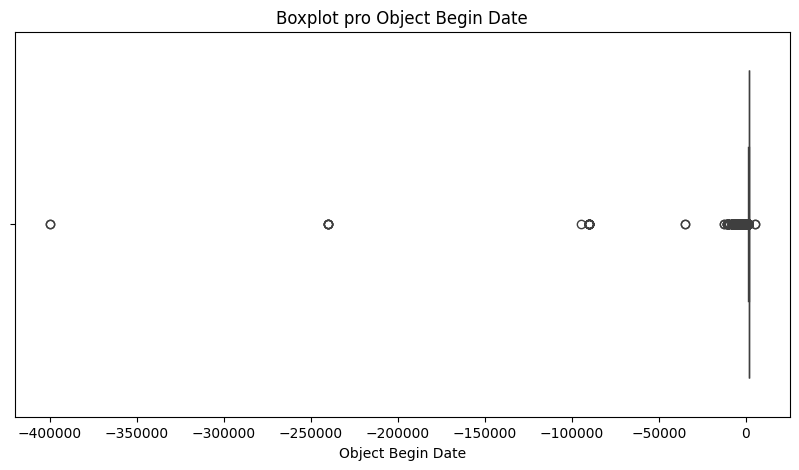

In [6]:
#Boxplot
object_begin_date = df['Object Begin Date'].dropna()
plt.figure(figsize=(10, 5))
sns.boxplot(x=object_begin_date)
plt.title("Boxplot pro Object Begin Date")
plt.xlabel("Object Begin Date")
plt.show()

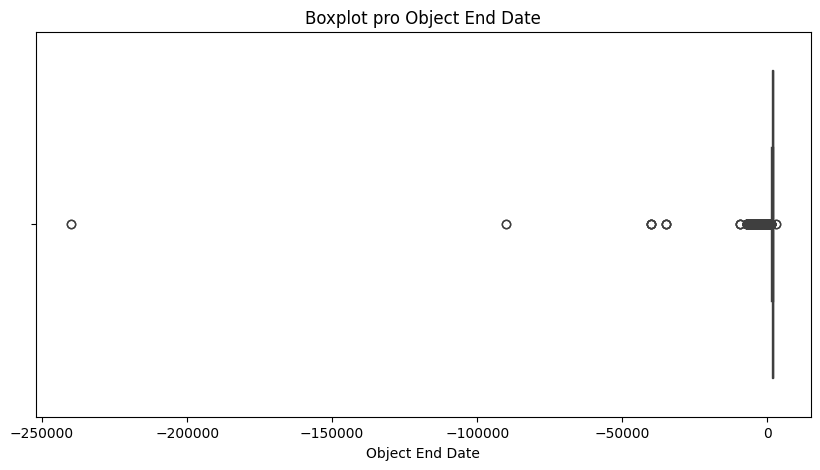

In [7]:
#Boxplot
object_end_date = df['Object End Date'].dropna()
plt.figure(figsize=(10, 5))
sns.boxplot(x=object_end_date)
plt.title("Boxplot pro Object End Date")
plt.xlabel("Object End Date")
plt.show()

In [8]:
#IQR Metoda
object_end_date = df['Object End Date'].dropna()

Q1 = object_end_date.quantile(0.15)
Q3 = object_end_date.quantile(0.85)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = object_end_date[(object_end_date < lower_bound) | (object_end_date > upper_bound)]

print("Počet outlierů:", len(outliers))
display(outliers)

Počet outlierů: 6636


20953    -4975.0
20954    -2000.0
20956    -2000.0
30771    -2400.0
30772    -2400.0
           ...  
434692   -1981.0
434693   -1981.0
434694   -1981.0
434695   -1981.0
481014   -1950.0
Name: Object End Date, Length: 6636, dtype: float64

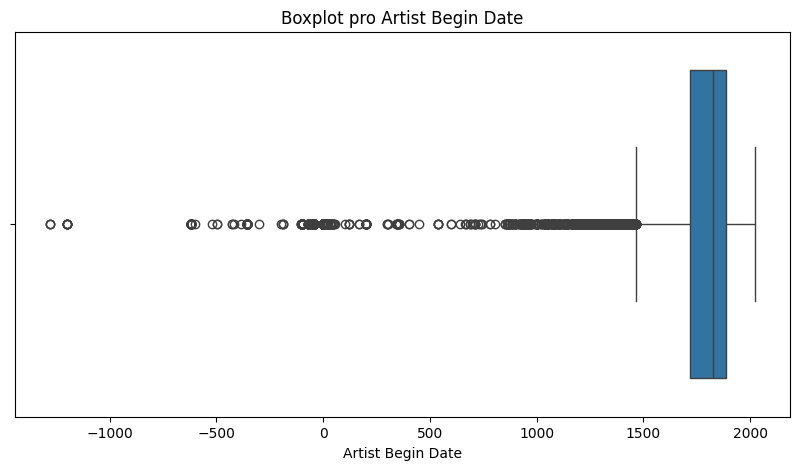

In [9]:
#Boxplot
artist_begin_date = df['Artist Begin Date'].dropna()
plt.figure(figsize=(10, 5))
sns.boxplot(x=artist_begin_date)
plt.title("Boxplot pro Artist Begin Date")
plt.xlabel("Artist Begin Date")
plt.show()

In [10]:
#Percentilový přístup
artist_begin_dates = df['Artist Begin Date'].dropna()

lower_bound = np.percentile(artist_begin_dates, 1)
upper_bound = np.percentile(artist_begin_dates, 99)

outliers = artist_begin_dates[(artist_begin_dates < lower_bound) | (artist_begin_dates > upper_bound)]

print("Počet outlierů:", len(outliers))
print("Příklady outlierů:", outliers.head())
print("Dolní hranice (1. percentil):", lower_bound)
print("Horní hranice (99. percentil):", upper_bound)


Počet outlierů: 4666
Příklady outlierů: 5049   -106.0
9294    -70.0
9295    -70.0
9296    -70.0
9297    -70.0
Name: Artist Begin Date, dtype: float64
Dolní hranice (1. percentil): 1370.0
Horní hranice (99. percentil): 1961.0


### 6: Detekce chybějících hodnot a jejich imputace
*Detekce chybějících hodnot:* Byl zjištěn počet chybějících hodnot v každém z vybraných tří sloupců('Artist Nationality', 'Country', 'Artist Display Bio'). Prázdné řetězce byly nahrazeny hodnotou NaN. Sloupce byly převedeny na string pro snažší zpracování hodnot.

*Imputace:*
Vytvořena funkce infer_nationality_from_country, která vrací název země uvedené v Country beze změny.
V případě, že Artist Nationality zůstala nevyplněná a Country nebylo k dispozici, byla hledána klíčová slova odpovídající národnostem ve sloupci Artist Display Bio.
Pomocí regulárního výrazu jsme v Artist Display Bio identifikovali slova končící na typické přípony národností (ian, ese, ish, an).
Pokud byl klíč nalezen, byla hodnota použita.

In [11]:
missing_data_counts = df[['Artist Nationality', 'Country', 'Artist Display Bio']].isnull().sum()
print("Počet chybějících hodnot v každém sloupci:")
print(missing_data_counts)

df['Artist Nationality'] = df['Artist Nationality'].replace('', np.nan).astype('string')
df['Country'] = df['Country'].replace('', np.nan).astype('string')
df['Artist Display Bio'] = df['Artist Display Bio'].replace('', np.nan).astype('string')

print("Typy dat po konverzi:")
print(df[['Artist Nationality', 'Country', 'Artist Display Bio']].dtypes)

Počet chybějících hodnot v každém sloupci:
Artist Nationality    202443
Country               408949
Artist Display Bio    204533
dtype: int64
Typy dat po konverzi:
Artist Nationality    string[python]
Country               string[python]
Artist Display Bio    string[python]
dtype: object


In [12]:
def infer_nationality_from_country(country):
    if pd.isna(country):
        return np.nan
    return country.strip()

def impute_artist_nationality(df):
    df['Artist Nationality'] = df['Artist Nationality'].combine_first(
        df['Country'].apply(infer_nationality_from_country)
    )

    nationality_suffixes = ['ian', 'ese', 'ish', 'an']
    pattern = r'\b(\w+?(ian|ese|ish|an))\b'

    def infer_nationality_from_bio(bio):
        if pd.isna(bio):
            return np.nan
        match = re.search(pattern, bio.lower())
        if match:
            return match.group(1).capitalize()
        return np.nan

    df['Artist Nationality'] = df['Artist Nationality'].combine_first(
        df['Artist Display Bio'].apply(infer_nationality_from_bio)
    )

    return df

df = impute_artist_nationality(df)
df['Artist Nationality'].head(25)

0      American
1      American
2           NaN
3           NaN
4           NaN
5           NaN
6           NaN
7           NaN
8           NaN
9      American
10     American
11     American
12     American
13     American
14       Mexico
15       Mexico
16       Mexico
17       Mexico
18       Mexico
19       Mexico
20       Mexico
21    Guatemala
22    Guatemala
23       Mexico
24       Mexico
Name: Artist Nationality, dtype: object

### 7: Čištění 'Medium'

Identifikace nejčastějších materiálů:
Z textových hodnot ve sloupci Medium jsou odstraněny NaN hodnoty a text převeden na malá písmena. explode() rozloží jednotlivé materiály do samostatných řádků, aby bylo možné efektivně spočítat jejich četnost pomocí value_counts(). expolde() odstraní mezeru před názvy sloupců. Prázdným hodnotám je přiřazen NaN(vytvořeno s pomocí ChatGPT).
Ze získaných materiálů je extrahováno 50 nejčastějších hodnot, ktere jsou uloženy do seznamu top_materials.

Pro každý materiál v seznamu materials je procházen sloupec Medium a kontroluje se, zda text obsahuje konkrétní materiál jako samostatné slovo. Pokud daný materiál v textu existuje, hodnota ve sloupci je nastavena na 1, jinak na 0. Pokud žádný z top materiálů není přítomen v daném záznamu, je přiřazen do sloupce Other.


In [13]:
def clean_material_data(df):
    material_counts = (
        df['Medium']
        .dropna()
        .str.lower()
        .str.replace(r'\s+', ' ', regex=True)
        .str.strip()
        .str.split(r',|\sand\s|/')
        .explode()
        .replace('', np.nan)
        .dropna()
        .str.strip()
        .value_counts()
    )
# Code assistance provided by ChatGPT, an AI model by OpenAI.
# For more details, visit https://openai.com.

    top_materials = material_counts.head(50).index.str.strip().tolist()

    def extract_material_features(df, materials):
        for material in materials:
            df[material] = df['Medium'].str.contains(rf'\b{material}\b', flags=re.IGNORECASE, na=False).astype(int)

        df['Other'] = (df[materials].sum(axis=1) == 0).astype(int)
        return df

    df = extract_material_features(df, top_materials)
    return df, top_materials

df, top_materials = clean_material_data(df)
df[[*top_materials, 'Other']].head(20)


,etching,silk,terracotta,commercial color lithograph,engraving,pen,gold,wood,silver,cotton,gelatin silver print,glass,albumen photograph,bronze,ink,lithograph,wool,watercolor,steel,metal,leather,film negative,faience,color on paper,paint,woodcut,linen,brush,graphite,albumen silver print from glass negative,brown ink,iron,black ink,copper,limestone,oil on canvas,brass,ivory,commercial color photolithograph,ceramic,pottery,commercial photolithograph,albumen silver print,gouache,wood engraving,hard-paste porcelain,hand-colored etching,stone,aquatint,woodblock print; ink,Other
0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
5,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
6,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
7,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
8,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
9,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


### 8: Extrakce rozměrů

*Logika extrakce:* Jsou použity regulární výrazy k identifikaci a extrakci jednotlivých rozměrů podle označení (H. pro height, W. pro width, D. pro depth, a Diam. pro průměr).
Pokud je nalezen pouze průměr (Diam.), je nastaven jako hodnota pro šířku a hloubku.
Pro data obsahující výšku (H.) a průměr (Diam.) je průměr považován za hodnotu šířky a hloubky, zatímco hodnota height je přímo přiřazena z výšky.

*Konverze jednotek:* Všechny hodnoty jsou převedeny na centimetry.

*Kontrola a výsledné přiřazení hodnot:* Každý záznam je následně uložen s extrahovanými hodnotami. Výsledné rozměry jsou integrovány do nových sloupců Height, Width a Depth.

Část tohoto kódu byla napsána s pomocí ChatGPT

In [14]:
def extract_dimensions(dimension_text):
    width, depth, height = None, None, None

    if pd.notna(dimension_text):
        cm_dimensions = re.search(r'\(([\d\s\.,x]+)\s*cm\)', dimension_text)

        if cm_dimensions:
            cm_values = [float(val.replace(",", ".")) for val in re.findall(r'(\d+(?:\.\d+)?)', cm_dimensions.group(1))]

            if "H." in dimension_text and len(cm_values) == 1:
                height = cm_values[0]
            elif len(cm_values) == 1 and "Diam." in dimension_text:
                width = depth = cm_values[0]
            elif len(cm_values) == 2:
                width, height = cm_values
            elif len(cm_values) >= 3:
                width, depth, height = cm_values[:3]

        height_match = re.search(r'H\.\s*(\d+(?:\.\d+)?)\s*(cm|mm|in)?', dimension_text)
        diameter_match = re.search(r'Diam\.\s*(\d+(?:\.\d+)?)\s*(cm|mm|in)?', dimension_text)

        if height_match and height is None:
            height = float(height_match.group(1).replace(",", "."))
            unit = height_match.group(2).lower() if height_match.group(2) else 'cm'
            if unit == 'in':
                height *= 2.54

        if diameter_match and width is None and depth is None:
            diameter = float(diameter_match.group(1).replace(",", "."))
            unit = diameter_match.group(2).lower() if diameter_match.group(2) else 'cm'
            if unit == 'in':
                diameter *= 2.54
            width = depth = diameter

    return width, depth, height

df[['Width', 'Depth', 'Height']] = df['Dimensions'].apply(lambda x: pd.Series(extract_dimensions(x)))
print(df[['Dimensions', 'Width', 'Depth', 'Height']].head(20))
# Code assistance provided by ChatGPT, an AI model by OpenAI.
# For more information, see https://openai.com.


                  Dimensions  Width  Depth  Height
0     Dimensions unavailable    NaN    NaN     NaN
1     Dimensions unavailable    NaN    NaN     NaN
2   Diam. 11/16 in. (1.7 cm)    1.7    1.7     NaN
3   Diam. 11/16 in. (1.7 cm)    1.7    1.7     NaN
4   Diam. 11/16 in. (1.7 cm)    1.7    1.7     NaN
5   Diam. 11/16 in. (1.7 cm)    1.7    1.7     NaN
6   Diam. 11/16 in. (1.7 cm)    1.7    1.7     NaN
7   Diam. 11/16 in. (1.7 cm)    1.7    1.7     NaN
8   Diam. 11/16 in. (1.7 cm)    1.7    1.7     NaN
9     Dimensions unavailable    NaN    NaN     NaN
10    Dimensions unavailable    NaN    NaN     NaN
11    Dimensions unavailable    NaN    NaN     NaN
12    Dimensions unavailable    NaN    NaN     NaN
13    Dimensions unavailable    NaN    NaN     NaN
14    Diam. 1/2 in. (1.3 cm)    1.3    1.3     NaN
15  Diam. 1 1/8 in. (2.9 cm)    2.9    2.9     NaN
16  Diam. 1 1/8 in. (2.9 cm)    2.9    2.9     NaN
17  Diam. 1 1/8 in. (2.9 cm)    2.9    2.9     NaN
18  Diam. 1 1/8 in. (2.9 cm)   